평가 기준은 [평가 기준 문서](docs/evaluation_criteria.md)를 참고하세요.

## 평가 개요

- DenseNet121 + U-MultiClass 모델의 저장된 가중치를 불러와 평가합니다.
- 현재 실행 결과는 pilot 테스트 이미지 100장을 대상으로 합니다.
- 학습과 동일한 전처리를 적용하고, DataLoader로 전체 테스트 이미지의 예측 결과를 수집합니다.
- 심비대·폐부종·흉수의 소견별 성능, 단일·복합 소견별 성능 및 오분류 사례를 확인합니다.
- 예측 결과, 평가 지표, 시각화 결과와 평가 설정을 저장합니다.

현재 결과는 pilot 평가 결과이며, 최종 학습 모델의 평가 결과와 구분합니다.

## 1. 라이브러리 및 라벨 규칙

In [1]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
)

# 소견 순서
FINDINGS = ["Cardiomegaly", "Edema", "Pleural Effusion"]
FINDING_NAMES = ["심비대", "폐부종", "흉수"]

# 클래스 순서
CLASS_NAMES = ["음성", "양성", "불확실"]
CLASS_LABELS = [0, 1, 2]

## 2. 모델 예측 결과 불러오기

In [2]:
import numpy as np

from pathlib import Path

# 노트북이 프로젝트의 evaluation 폴더에 있는 기준
PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "evaluation":
    PROJECT_DIR = PROJECT_DIR.parent

IMAGE_ROOT = Path("/home/team30103/physionet_data")
CSV_DIR = PROJECT_DIR / "data" / "processed" / "pilot"

MODEL_PATH = (
    PROJECT_DIR / "runs" / "pilot"
    / "train_20261015_095921_874554"
    / "best_model.pth"
)

print("프로젝트 경로:", PROJECT_DIR)
print("이미지 폴더 존재:", IMAGE_ROOT.is_dir())
print("test CSV 존재:", (CSV_DIR / "pilot_test.csv").is_file())
print("모델 파일 존재:", MODEL_PATH.is_file())

정답 형태: (2, 3)
예측 확률 형태: (2, 3, 3)
예측 클래스 형태: (2, 3)


In [ ]:
import torch
from torch import nn
from torchvision.models import densenet121

# GPU가 없으면 CPU 사용
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 학습 때와 같은 모델 구조
class CXRModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = densenet121(weights=None)
        self.backbone.classifier = nn.Linear(
            self.backbone.classifier.in_features, 9
        )

    def forward(self, images):
        return self.backbone(images).reshape(-1, 3, 3)


# 저장된 checkpoint 불러오기
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

# 소견·클래스 순서 확인
assert checkpoint["target_labels"] == [
    "Cardiomegaly", "Edema", "Pleural Effusion"
]
assert checkpoint["class_names"] == [
    "negative", "positive", "uncertain"
]
if checkpoint.get("smoke_test", False):
    raise ValueError("임시 데이터로 학습한 demo 모델입니다.")

# 학습된 가중치 적용
model = CXRModel()
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("사용 장치:", device)
print("저장 당시 epoch:", checkpoint["epoch"])
print("학습된 모델 불러오기 완료")

In [ ]:
import sys
import pandas as pd
from torch.utils.data import DataLoader

# 프로젝트의 전처리 코드 사용
sys.path.insert(0, str(PROJECT_DIR))
from cxr_preprocessing import CXRDataset

# test CSV 읽기
test_df = pd.read_csv(
    CSV_DIR / "pilot_test.csv",
    dtype={"dicom_id": "string"}
)

# IMAGE_ROOT 바로 아래에 이미지가 모여 있는 기준
test_df["image_path"] = test_df["dicom_id"].map(
    lambda image_id: str(IMAGE_ROOT / f"{image_id}.jpg")
)

# 이미지 누락 확인
missing = test_df["image_path"].map(
    lambda path: not Path(path).is_file()
)

if missing.any():
    raise FileNotFoundError(
        f"test 이미지 {missing.sum()}장 누락. "
        f"첫 누락 경로: {test_df.loc[missing, 'image_path'].iloc[0]}"
    )

# 학습과 동일한 전처리·라벨 변환 적용
test_dataset = CXRDataset(
    test_df,
    image_size=checkpoint["input"]["height"]
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

print("test 이미지 수:", len(test_dataset))
print("test 배치 수:", len(test_loader))
print("test DataLoader 준비 완료")

In [ ]:
true_batches = []
prob_batches = []

model.eval()

with torch.inference_mode():
    for batch_idx, (images, labels) in enumerate(test_loader, start=1):
        images = images.to(device)

        logits = model(images)
        probs = logits.softmax(dim=-1)

        true_batches.append(labels.cpu())
        prob_batches.append(probs.cpu())

        print(f"예측 진행: {batch_idx}/{len(test_loader)} 배치")

# 전체 배치 결과 합치기
y_true = torch.cat(true_batches).numpy()
y_prob = torch.cat(prob_batches).numpy()
y_pred = y_prob.argmax(axis=-1)

print("정답 형태:", y_true.shape)
print("예측 확률 형태:", y_prob.shape)
print("예측 클래스 형태:", y_pred.shape)

In [3]:
assert y_true.shape == (len(y_true), 3)
assert y_prob.shape == (len(y_true), 3, 3)
assert y_pred.shape == (len(y_true), 3)

assert np.allclose(y_prob.sum(axis=2), 1.0, atol=1e-5)
assert np.array_equal(y_pred, np.argmax(y_prob, axis=2))

print("모델-평가 데이터 형식 검증 완료")

모델-평가 데이터 형식 검증 완료


## 3. 입력 데이터 검증

In [4]:
# 정답과 예측 확률의 형태 확인
assert y_true.ndim == 2 and y_true.shape[1] == 3
assert y_prob.shape == (len(y_true), 3, 3)
assert y_pred.shape == y_true.shape

# 정답 코드가 0, 1, 2인지 확인
assert np.isin(y_true, [0, 1, 2]).all()

# 확률이 유효한지 확인
assert np.isfinite(y_prob).all()
assert ((y_prob >= 0) & (y_prob <= 1)).all()
assert np.allclose(y_prob.sum(axis=2), 1)

정답 형태: (2, 3)
예측 확률 형태: (2, 3, 3)
예측 코드 형태: (2, 3)


## 4. 소견별 성능 평가

In [5]:
for i, finding in enumerate(FINDING_NAMES):
    print(f"\n===== {finding} =====")

    print(classification_report(
        y_true[:, i],
        y_pred[:, i],
        labels=CLASS_LABELS,
        target_names=CLASS_NAMES,
        zero_division=0
    ))


===== 심비대 =====
              precision    recall  f1-score   support

          음성       0.00      0.00      0.00       1.0
          양성       0.00      0.00      0.00       0.0
         불확실       0.00      0.00      0.00       1.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0


===== 폐부종 =====
              precision    recall  f1-score   support

          음성       0.00      0.00      0.00         1
          양성       0.50      1.00      0.67         1
         불확실       0.00      0.00      0.00         0

    accuracy                           0.50         2
   macro avg       0.17      0.33      0.22         2
weighted avg       0.25      0.50      0.33         2


===== 흉수 =====
              precision    recall  f1-score   support

          음성       0.00      0.00      0.00       0.0
          양성       0.00      0.00      0.00       1.0
         불확실       0.00  

In [6]:
for i, finding in enumerate(FINDING_NAMES):
    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=CLASS_LABELS
    )

    cm_df = pd.DataFrame(
        cm,
        index=[f"실제 {name}" for name in CLASS_NAMES],
        columns=[f"예측 {name}" for name in CLASS_NAMES]
    )

    print(f"===== {finding} 혼동행렬 =====")
    display(cm_df)

===== 심비대 혼동행렬 =====


,예측 음성,예측 양성,예측 불확실
실제 음성,0,1,0
실제 양성,0,0,0
실제 불확실,0,1,0


===== 폐부종 혼동행렬 =====


,예측 음성,예측 양성,예측 불확실
실제 음성,0,1,0
실제 양성,0,1,0
실제 불확실,0,0,0


===== 흉수 혼동행렬 =====


,예측 음성,예측 양성,예측 불확실
실제 음성,0,0,0
실제 양성,1,0,0
실제 불확실,1,0,0


In [7]:
# AUROC 평가

auroc_results = []

for i, finding in enumerate(FINDING_NAMES):
    # 해당 소견의 불확실 정답 제외
    mask = np.isin(y_true[:, i], [0, 1])

    true_binary = y_true[mask, i]
    negative_prob = y_prob[mask, i, 0]
    positive_prob = y_prob[mask, i, 1]

    raw_auroc = np.nan
    normalized_auroc = np.nan

    # 음성과 양성이 모두 있어야 계산 가능
    if len(np.unique(true_binary)) == 2:
        raw_auroc = roc_auc_score(
            true_binary, positive_prob
        )

        denominator = negative_prob + positive_prob

        # 0으로 나누는 경우 방지
        if np.all(denominator > 0):
            normalized_score = positive_prob / denominator

            normalized_auroc = roc_auc_score(
                true_binary, normalized_score
            )

    auroc_results.append({
        "소견": finding,
        "평가 이미지 수": int(mask.sum()),
        "음성 수": int((true_binary == 0).sum()),
        "양성 수": int((true_binary == 1).sum()),
        "3클래스 양성 확률 AUROC": raw_auroc,
        "양성·음성 정규화 AUROC": normalized_auroc,
    })

auroc_df = pd.DataFrame(auroc_results)
display(auroc_df)

,소견,평가 이미지 수,음성 수,양성 수,3클래스 양성 확률 AUROC,양성·음성 정규화 AUROC
0,심비대,1,1,0,NaN,NaN
1,폐부종,2,1,1,1.0,1.0
2,흉수,1,0,1,NaN,NaN


In [8]:
from sklearn.metrics import precision_recall_curve, auc

auprc_results = []

for i, finding in enumerate(FINDING_NAMES):
    # 해당 소견의 불확실 정답 제외
    mask = np.isin(y_true[:, i], [0, 1])

    true_binary = y_true[mask, i]
    negative_prob = y_prob[mask, i, 0]
    positive_prob = y_prob[mask, i, 1]

    denominator = negative_prob + positive_prob
    auprc = np.nan

    # 음성·양성이 모두 있고, 정규화가 가능할 때 계산
    if (
        len(np.unique(true_binary)) == 2
        and np.all(denominator > 0)
    ):
        normalized_score = positive_prob / denominator

        precision, recall, _ = precision_recall_curve(
            true_binary, normalized_score
        )

        auprc = auc(recall, precision)

    auprc_results.append({
        "소견": finding,
        "평가 이미지 수": int(mask.sum()),
        "양성 비율": (
            float((true_binary == 1).mean())
            if len(true_binary) > 0 else np.nan
        ),
        "정규화 AUPRC (사다리꼴)": auprc,
    })

auprc_df = pd.DataFrame(auprc_results)
display(auprc_df)

,소견,평가 이미지 수,양성 비율,정규화 AUPRC (사다리꼴)
0,심비대,1,0.0,NaN
1,폐부종,2,0.5,1.0
2,흉수,1,1.0,NaN


In [15]:
from sklearn.metrics import average_precision_score

additional_results = []

for i, finding in enumerate(FINDING_NAMES):

    # 불확실 정답 제외
    mask = np.isin(y_true[:, i], [0, 1])

    true = y_true[mask, i]
    pred = y_pred[mask, i]
    positive_prob = y_prob[mask, i, 1]

    # 양성 탐지 기준 (불확실 예측은 정답으로 인정하지 않음)
    tp = np.sum((true == 1) & (pred == 1))
    fn = np.sum((true == 1) & (pred != 1))
    tn = np.sum((true == 0) & (pred == 0))
    fp = np.sum((true == 0) & (pred != 0))

    sensitivity = (
        tp / (tp + fn) if (tp + fn) > 0 else np.nan
    )
    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else np.nan
    )

    ap = (
        average_precision_score(true, positive_prob)
        if len(np.unique(true)) == 2
        else np.nan
    )

    additional_results.append({
        "소견": finding,
        "평가 이미지 수": len(true),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "AP": ap
    })

additional_df = pd.DataFrame(additional_results)
display(additional_df)

,소견,평가 이미지 수,Sensitivity,Specificity,AP
0,심비대,1,NaN,0.0,NaN
1,폐부종,2,1.0,0.0,1.0
2,흉수,1,0.0,NaN,NaN


## 5. 단일·복합 소견별 성능 비교

In [9]:
# 복합 소견별 성능 비교

# 세 소견 중 불확실 정답이 없는 이미지
certain_mask = (y_true != 2).all(axis=1)

# 이미지별 실제 양성 소견 개수
positive_count = (y_true ==1). sum(axis=1)

groups = {
    "양성 소견 0개": certain_mask & (positive_count == 0),
    "단일 소견 (양성 1개)": certain_mask & (positive_count == 1),
    "복합 소견 (양성 2~3개)": certain_mask & (positive_count >=2),
}

group_results = []

for group_name, mask in groups.items():
    n = int(mask.sum())

    if n>0:
        # 이미지마다 세 소견을 모두 맞혔는지 확인
        exact_match = (
            y_true[mask] == y_pred[mask]
        ).all(axis=1).mean()

        # 전체 소견 판단 중 맞힌 비율
        finding_accuracy = (
            y_true[mask] == y_pred[mask]
        ).mean()
    else:
        exact_match = np.nan
        finding_accuracy = np.nan

    group_results.append({
        "그룹": group_name,
        "이미지 수": n,
        "세 소견 모두 정답 비율": exact_match,
        "소견별 판단 정확도": finding_accuracy,
    })

group_df = pd.DataFrame(group_results)
display(group_df)

,그룹,이미지 수,세 소견 모두 정답 비율,소견별 판단 정확도
0,양성 소견 0개,0,NaN,NaN
1,단일 소견 (양성 1개),0,NaN,NaN
2,복합 소견 (양성 2~3개),0,NaN,NaN


## 6. 결과 시각화

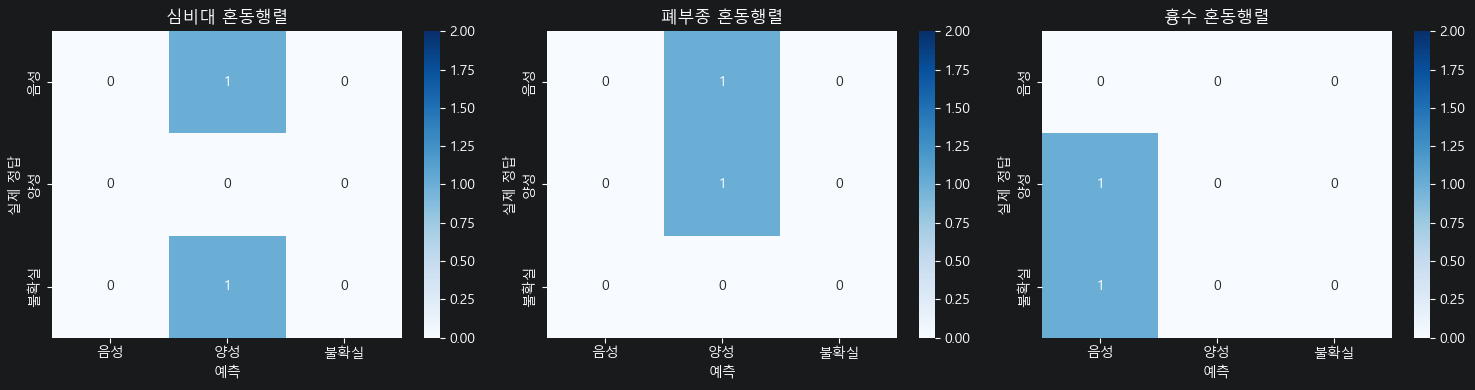

In [10]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = PROJECT_DIR / "evaluation" / "MALGUN.TTF"
fm.fontManager.addfont(str(font_path))

plt.rcParams["font.family"] = fm.FontProperties(
    fname=str(font_path)
).get_name()
plt.rcParams["axes.unicode_minus"] = False

# 시각화 결과 저장 폴더
SAVE_DIR = PROJECT_DIR / "evaluation" / "results" / MODEL_PATH.parent.name
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("저장 폴더:", SAVE_DIR)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Windows 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, finding in enumerate(FINDING_NAMES):
    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=CLASS_LABELS
    )

    sns.heatmap(
        cm,
        annot=True,             # 칸 안에 숫자 표시
        fmt="d",                # 정수로 표시
        cmap="Blues",           # 숫자가 클수록 진한 파란색
        vmin=0,
        vmax=len(y_true),       # 세 그래프의 색 기준 통일
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=axes[i]
    )

    axes[i].set_title(f"{finding} 혼동행렬")
    axes[i].set_xlabel("예측")
    axes[i].set_ylabel("실제 정답")

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

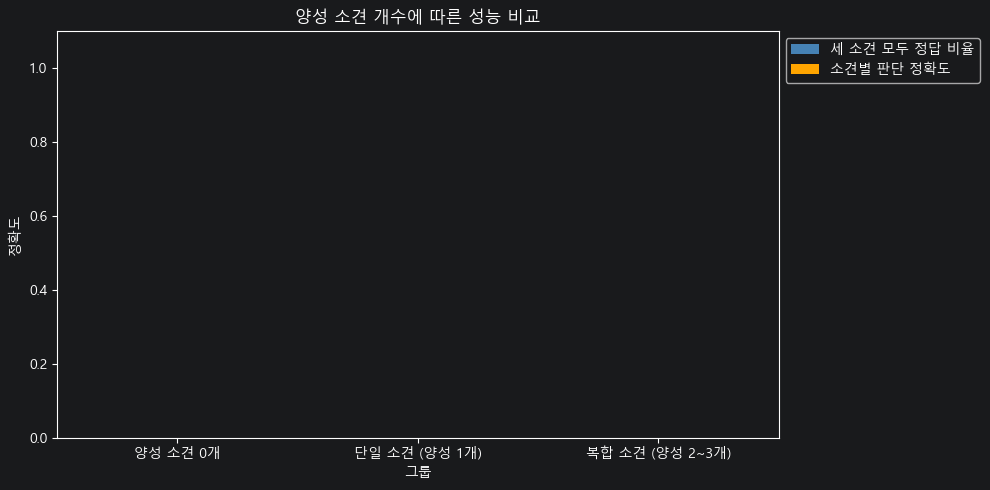

In [11]:
ax = group_df.plot(
    x="그룹",
    y=["세 소견 모두 정답 비율", "소견별 판단 정확도"],
    kind="bar",
    figsize=(10, 5),
    rot=0,
    color=["steelblue", "orange"]
)

ax.set_title("양성 소견 개수에 따른 성능 비교")
ax.set_xlabel("그룹")
ax.set_ylabel("정확도")
ax.set_ylim(0, 1.1)

ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "finding_groups.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. 오분류 사례 분석

In [12]:
error_results = []

for image_idx in range(len(y_true)):
    for finding_idx, finding in enumerate(FINDING_NAMES):
        true_label = int(y_true[image_idx, finding_idx])
        pred_label = int(y_pred[image_idx, finding_idx])

        # 정답과 예측이 다른 경우만 기록
        if true_label != pred_label:
            error_results.append({
                "이미지 번호": image_idx + 1,
                "소견": finding,
                "실제 정답": CLASS_NAMES[true_label],
                "모델 예측": CLASS_NAMES[pred_label],
                "예측 클래스 확률": y_prob[
                    image_idx, finding_idx, pred_label
                ],
            })

error_df = pd.DataFrame(
    error_results,
    columns=[
        "이미지 번호", "소견", "실제 정답",
        "모델 예측", "예측 클래스 확률"
    ]
)

display(error_df)

,이미지 번호,소견,실제 정답,모델 예측,예측 클래스 확률
0,1,심비대,음성,양성,0.640130
1,1,흉수,불확실,음성,0.788076
2,2,심비대,불확실,양성,0.630867
3,2,폐부종,음성,양성,0.827484
4,2,흉수,양성,음성,0.787162


In [13]:
# 1. 소견별 오분류 개수
error_counts = (
    error_df.groupby("소견")
    .size()
    .reindex(FINDING_NAMES, fill_value=0)
    .rename("오분류 개수")
)

print("===== 소견별 오분류 개수 =====")
print(error_counts.to_string())

# 2. 소견별 오류 유형
error_types = (
    error_df.groupby(["소견", "실제 정답", "모델 예측"])
    .size()
    .reset_index(name="개수")
)

print("\n===== 소견별 오류 유형 =====")
print(error_types.to_string(index=False))

===== 소견별 오분류 개수 =====
소견
심비대    2
폐부종    1
흉수     2

===== 소견별 오류 유형 =====
 소견 실제 정답 모델 예측  개수
심비대   불확실    양성   1
심비대    음성    양성   1
폐부종    음성    양성   1
 흉수   불확실    음성   1
 흉수    양성    음성   1


In [ ]:
import json
from datetime import datetime

# 모델 실행 폴더명별로 결과 저장
SAVE_DIR = PROJECT_DIR / "evaluation" / "results" / MODEL_PATH.parent.name
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. 정답·예측 확률·예측 클래스·이미지 ID 저장
np.savez_compressed(
    SAVE_DIR / "predictions_test.npz",
    y_true=y_true,
    y_prob=y_prob,
    y_pred=y_pred,
    dicom_id=test_df["dicom_id"].astype(str).to_numpy(dtype=str)
)

# 2. 평가 지표 표 저장
tables = {
    "auroc": auroc_df,
    "auprc": auprc_df,
    "additional_metrics": additional_df,
    "finding_groups": group_df,
    "misclassifications": error_df,
}

for name, table in tables.items():
    table.to_csv(
        SAVE_DIR / f"{name}.csv",
        index=False,
        encoding="utf-8-sig"
    )

# 3. 소견별 precision·recall·F1 등 저장
reports = {
    finding: classification_report(
        y_true[:, i],
        y_pred[:, i],
        labels=CLASS_LABELS,
        target_names=CLASS_NAMES,
        zero_division=0,
        output_dict=True
    )
    for i, finding in enumerate(FINDINGS)
}

(SAVE_DIR / "classification_reports.json").write_text(
    json.dumps(reports, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# 4. 어떤 모델과 데이터로 평가했는지 기록
info = {
    "evaluated_at": datetime.now().astimezone().isoformat(),
    "model_path": str(MODEL_PATH),
    "test_csv": str(CSV_DIR / "pilot_test.csv"),
    "image_root": str(IMAGE_ROOT),
    "test_image_count": len(y_true),
    "saved_epoch": checkpoint["epoch"],
    "training_config": checkpoint.get("config"),
    "finding_order": FINDINGS,
    "class_order": CLASS_NAMES,
    "prediction_rule": "소견별 3클래스 확률의 argmax",
}

(SAVE_DIR / "evaluation_info.json").write_text(
    json.dumps(info, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("평가 결과 저장 완료:", SAVE_DIR)